setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
ZIP_PATH = ROOT / "data/raw/CCDB_Export_7_August_2024_through_October_2024.zip"
CACHE = ROOT / "data/processed/narratives_aug_oct_2024.csv"
FIG_DIR = ROOT / "reports/figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
print(ROOT, "| zip found:", ZIP_PATH.exists())

e:\complaint-classifier | zip found: True


load narratives only, cached

In [2]:
NARR = "Consumer complaint narrative"
USE = ["Complaint ID", "Date received", "Product", "Issue", NARR]

if CACHE.exists():
    df = pd.read_csv(CACHE, dtype=str)
else:
    parts = []
    for chunk in pd.read_csv(ZIP_PATH, compression="zip", usecols=USE,
                             dtype=str, chunksize=200_000):
        chunk[NARR] = chunk[NARR].fillna("").str.strip()
        parts.append(chunk[chunk[NARR] != ""])
    df = pd.concat(parts, ignore_index=True)
    df.to_csv(CACHE, index=False)

df = df.rename(columns={NARR: "text"})
assert len(df) == 229_944, len(df)   # must match the inspect script
print(df.shape)
df.head(3)

(229944, 5)


,Date received,Product,Issue,text,Complaint ID
0,2024-08-07,Credit reporting or other personal consumer re...,Improper use of your report,"Today, I noticed unauthorized inquiries on my ...",9737401
1,2024-08-07,Credit reporting or other personal consumer re...,Improper use of your report,"This morning, I discovered unauthorized inquir...",9731503
2,2024-08-29,Credit reporting or other personal consumer re...,Improper use of your report,I need your assistance with this incorrect acc...,9957624


class distribution

,count,share_%
Product,,
Credit reporting or other personal consumer reports,183664,79.9
Debt collection,18422,8.0
Credit card,8233,3.6
Checking or savings account,7570,3.3
Mortgage,3133,1.4
"Money transfer, virtual currency, or money service",2597,1.1
Student loan,2004,0.9
Vehicle loan or lease,1914,0.8
"Payday loan, title loan, personal loan, or advance loan",1331,0.6


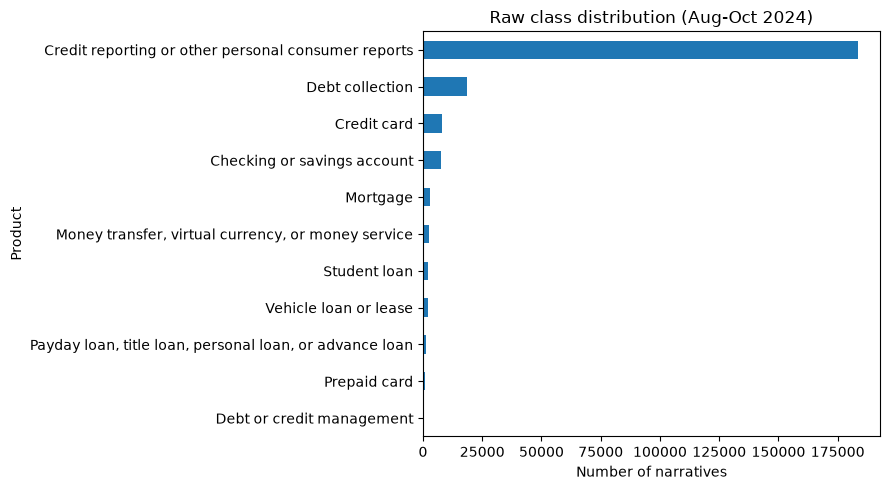

In [3]:
counts = df["Product"].value_counts()
display(pd.DataFrame({"count": counts, "share_%": (counts / len(df) * 100).round(1)}))

ax = counts.sort_values().plot.barh(figsize=(9, 5))
ax.set_xlabel("Number of narratives")
ax.set_title("Raw class distribution (Aug-Oct 2024)")
plt.tight_layout()
plt.savefig(FIG_DIR / "class_distribution_raw.png", dpi=150)
plt.show()

**Finding:** The classes are heavily imbalanced. "Credit reporting or other personal consumer reports" makes up 79.9% of all narratives (183,664 of 229,944), while the smallest classes (prepaid card, debt or credit management) have only 721 and 355 complaints.

**What it means:** A model that always predicts "credit reporting" would score about 80% accuracy and be useless. So I will use **macro-F1** as the main metric, which averages the F1 score of every class equally, and I will also look at per-class results and the confusion matrix. I will also cap the credit reporting class and drop the tiny classes so the benchmark is fair.

text length

count    229944.0
mean        168.0
std         225.0
min           1.0
50%         111.0
90%         339.0
95%         472.0
99%         991.0
max        5862.0
Name: n_words, dtype: float64

Product
Debt collection                                             97.0
Credit reporting or other personal consumer reports        104.0
Debt or credit management                                  114.0
Prepaid card                                               137.0
Payday loan, title loan, personal loan, or advance loan    143.0
Credit card                                                158.0
Student loan                                               162.0
Money transfer, virtual currency, or money service         163.0
Checking or savings account                                170.0
Vehicle loan or lease                                      173.0
Mortgage                                                   213.0
Name: n_words, dtype: float64


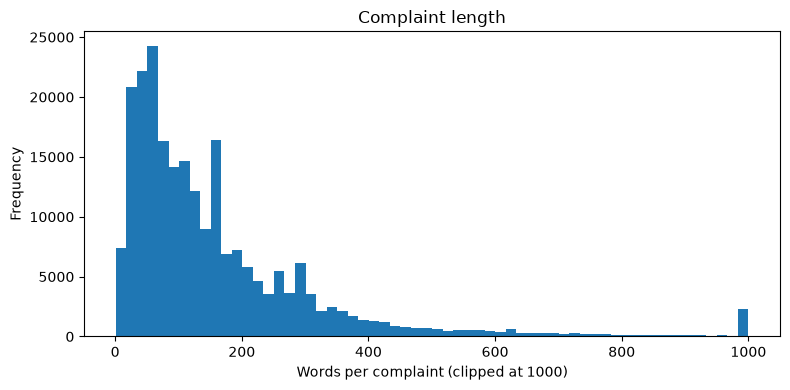

In [4]:
df["n_words"] = df["text"].str.split().str.len()
print(df["n_words"].describe(percentiles=[.5, .9, .95, .99]).round(0))
print()
print(df.groupby("Product")["n_words"].median().sort_values())

df["n_words"].clip(upper=1000).plot.hist(bins=60, figsize=(8, 4))
plt.xlabel("Words per complaint (clipped at 1000)")
plt.title("Complaint length")
plt.tight_layout()
plt.savefig(FIG_DIR / "text_length.png", dpi=150)
plt.show()

**Finding:** Complaints are 168 words long on average, but the median is 111 and the distribution has a long tail: the 90th percentile is 339 words, the 99th is 991, and the longest is 5,862. Mortgage complaints are the longest (median 213 words) and debt collection the shortest (median 97).

**What it means:** I do not need to keep the whole text of the longest complaints. I will pick a maximum sequence length near the 90th percentile so that most complaints are kept in full, while training stays affordable on CPU for the BiLSTM and on a Colab GPU for DistilBERT. Words are not tokens (a transformer splits words into pieces), so the final value will be chosen in the modelling step.

duplicate check, the leakage risk

In [5]:
norm = df["text"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
df["is_exact_dup"] = norm.duplicated(keep="first")
print("Exact duplicate narratives:", df["is_exact_dup"].sum(),
      f"({df['is_exact_dup'].mean():.1%})")
print()
print(df.groupby("Product")["is_exact_dup"].mean().mul(100).round(1)
        .sort_values(ascending=False))

openings = norm.str[:150].value_counts()
print("\nMost repeated 150-character openings:")
print(openings.head(5).rename("n_complaints").to_string())

Exact duplicate narratives: 105974 (46.1%)

Product
Credit reporting or other personal consumer reports        54.5
Debt collection                                            29.9
Credit card                                                 3.7
Payday loan, title loan, personal loan, or advance loan     1.3
Vehicle loan or lease                                       0.9
Prepaid card                                                0.7
Money transfer, virtual currency, or money service          0.4
Checking or savings account                                 0.2
Student loan                                                0.1
Mortgage                                                    0.0
Debt or credit management                                   0.0
Name: is_exact_dup, dtype: float64

Most repeated 150-character openings:
text
in accordance with the fair credit reporting act. the list of accounts below has violated my federally protected consumer rights to privacy and confid    10084
upon 

**Finding:** 105,974 narratives (46.1%) are exact copies of an earlier one, so only about 124,000 texts are unique. The problem is concentrated in credit reporting (54.5% duplicates) and debt collection (29.9%). The most common opening sentence appears 10,084 times, which looks like a templated letter.

**What it means:** If I split randomly, copies of the same letter would end up in both train and test, and the model would be rewarded for memorizing them instead of understanding the complaint. Duplicates must be removed before splitting. Exact matching is not enough, because templates with small changes (like a different account name) are not exact copies.

read some samples and check redaction

In [6]:
print("Share of complaints containing XXXX redaction:",
      round(df["text"].str.contains("XXXX", regex=False).mean(), 3))

for p in counts.index[:8]:
    print("=" * 80)
    print(p)
    for t in df[df["Product"] == p].sample(2, random_state=SEED)["text"]:
        print("-", t[:300].replace("\n", " "))

Share of complaints containing XXXX redaction: 0.601
Credit reporting or other personal consumer reports
- Please take a look at the attached letters and ID docs for verification that it is I XXXX XXXX XXXX filing this complaint. The stuff on my credit report is wrong and Under 15 U.S. Code 1681b Permissible purposes of consumer reports I never gave any written consent to report anything on my consumer r
- I filed a dispute for incorrect information on my credit report. I received an email from the credit bureau stating that they are assuming the disputes are coming from a 3rd party. They in fact did not come from a 3rd party. l even called them to verify it was me and they still refused to process my
Debt collection
- I WOKE UP THIS MORNING CHECKED MY CREDIR REPORT AND NOTICED THAT THIS ACCOUNT IM REPORTING TO BE BLOCKED AND DELETED IS STILL SHOWING ON MY REPORT AND AFFECTING MY CREDIBILITY.
- I am the original author of this complaint. I have been dealing with the frustrations of the

**Finding:** 60.1% of the complaints contain "XXXX", which is how the CFPB hides personal information such as names, dates and amounts. Reading the samples also showed label noise: one complaint filed under "Debt collection" is really about an incorrect item on a credit report.

**What it means:** The "XXXX" tokens carry no information, so the text cleaning step should treat them consistently instead of letting the model learn them as real words. The labels are the category the consumer chose when filing, not a verified ground truth, so some mistakes between similar classes (credit reporting vs debt collection) are expected and will be a limitation in the README.

proposed class plan, nothing saved yet

In [7]:
SELECTED = [
    "Credit reporting or other personal consumer reports",
    "Debt collection",
    "Credit card",
    "Checking or savings account",
    "Mortgage",
    "Money transfer, virtual currency, or money service",
    "Student loan",
    "Vehicle loan or lease",
]
CAP = 20_000

sel = df[df["Product"].isin(SELECTED) & ~df["is_exact_dup"]]
after_dedup = sel["Product"].value_counts()
plan = after_dedup.clip(upper=CAP)
display(pd.DataFrame({"after_dedup": after_dedup, "planned": plan}))
print("Planned total:", plan.sum())

,after_dedup,planned
Product,,
Credit reporting or other personal consumer reports,83574,20000
Debt collection,12911,12911
Credit card,7928,7928
Checking or savings account,7555,7555
Mortgage,3132,3132
"Money transfer, virtual currency, or money service",2587,2587
Student loan,2002,2002
Vehicle loan or lease,1896,1896


Planned total: 58011


**Note:** This first plan removes only exact duplicates and caps credit reporting at 20,000, giving 58,011 rows. I kept it to show the starting point, but the cells below show it is not enough, because template copies and label conflicts remain.

label conflicts: the same text filed under different products

In [8]:
df["norm"] = norm
df["prefix"] = df["norm"].str[:150]

n_labels = df.groupby("norm")["Product"].nunique()
conflict_texts = n_labels[n_labels > 1].index
print("Distinct texts filed under more than one Product:", len(conflict_texts))
print("Rows affected:", df["norm"].isin(conflict_texts).sum())

Distinct texts filed under more than one Product: 156
Rows affected: 10516


**Finding:** 156 distinct texts were filed under more than one product, which affects 10,516 rows (about 67 copies per text on average). These are templated letters submitted under different categories.

**What it means:** For these texts the label is essentially random, so training on them would teach the model noise. I will remove all of them.

near-duplicate template families, grouped by the first 150 characters

In [9]:
fam = df.groupby("prefix")["Product"].agg(n="size", n_products="nunique")
big = fam[fam["n"] >= 5]
rows_big = df[df["prefix"].isin(big.index)]
print("Template families (>=5 complaints sharing the same opening):", len(big))
print(f"Rows inside those families: {len(rows_big):,} ({len(rows_big) / len(df):.1%})")
print()
print(rows_big["Product"].value_counts())

Template families (>=5 complaints sharing the same opening): 2629
Rows inside those families: 123,818 (53.8%)

Product
Credit reporting or other personal consumer reports        117617
Debt collection                                              5585
Credit card                                                   533
Vehicle loan or lease                                          30
Payday loan, title loan, personal loan, or advance loan        27
Checking or savings account                                    16
Mortgage                                                        5
Debt or credit management                                       3
Student loan                                                    2
Name: count, dtype: int64


**Finding:** Grouping complaints by their first 150 characters, I found 2,629 template families with at least 5 complaints each. They cover 123,818 rows, which is 53.8% of the dataset, and 117,617 of those rows are credit reporting (about 64% of that class).

**What it means:** This is bigger than the 46.1% of exact duplicates, so exact matching alone would have missed a lot of near-copies. I will keep only one complaint per opening, chosen at random with a fixed seed. I will still measure train/test similarity after the split, because near-copies with a different opening could remain.

revised class plan: drop conflicts, keep one complaint per opening, then cap

In [10]:
shuffled = df.sample(frac=1, random_state=SEED)       # random, so survivors aren't picked by order
clean = shuffled[~shuffled["norm"].isin(conflict_texts)]
clean = clean.drop_duplicates(subset="prefix", keep="first")

print(f"Rows: {len(df):,} -> {len(clean):,} after removing label conflicts and template copies")

sel = clean[clean["Product"].isin(SELECTED)]
after = sel["Product"].value_counts()
plan = after.clip(upper=CAP)
display(pd.DataFrame({"after_cleaning": after, "planned": plan}))
print("Planned total:", plan.sum())

Rows: 229,944 -> 87,055 after removing label conflicts and template copies


,after_cleaning,planned
Product,,
Credit reporting or other personal consumer reports,47918,20000
Debt collection,12108,12108
Credit card,7622,7622
Checking or savings account,7502,7502
Mortgage,3121,3121
"Money transfer, virtual currency, or money service",2573,2573
Student loan,1991,1991
Vehicle loan or lease,1866,1866


Planned total: 56783


**Result:** After removing label conflicts and template copies, the dataset goes from 229,944 to 87,055 rows. After capping credit reporting at 20,000, the planned dataset has 56,783 rows across 8 classes: credit reporting 20,000, debt collection 12,108, credit card 7,622, checking or savings 7,502, mortgage 3,121, money transfer 2,573, student loan 1,991, vehicle loan 1,866.

**Decisions and limitations:** I dropped prepaid card, payday loan and debt management because they are too small for a fair benchmark. The smallest kept class (vehicle loan) will have only about 280 test examples, so its per-class scores will be noisy. This dataset is deliberately more balanced than reality (real credit reporting share is about 80%), so the scores describe this benchmark, not real production traffic.